In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

import seaborn as sns
import joblib

In [6]:
df = pd.read_csv("data.csv", sep=";")
print(df.head())

   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance\t  Previous qualification  \
0                             1                       1   
1                             1                       1   
2                             1                       1   
3                             1                       1   
4                             0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   
2                         

In [7]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget values:")
print(df["Target"].value_counts())

Dataset shape: (4424, 37)

Column names:
Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem 

In [8]:
df["Target"] = df["Target"].apply(
    lambda x: "Dropout" if x == "Dropout" else "Not Dropout"
)
print(df["Target"].value_counts())

Target
Not Dropout    3003
Dropout        1421
Name: count, dtype: int64


In [ ]:
x = df.drop("Target", axis=1)

y = df["Target"]

print("Input data shape:", x.shape)
print("Output data shape:", y.shape)

NameError: name 'X' is not defined

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (3539, 36)
Testing data: (885, 36)


In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
lr = LogisticRegression(max_iter=2000)
lr.fit(x_train_scaled, y_train)
lr_pred = lr.predict(x_test_scaled)
print("Logistic Regression Accuracy:",accuracy_score(y_test, lr_pred))

Logistic Regression Accuracy: 0.880225988700565


In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)
dt_pred = dt.predict(x_test)
print("Decision Tree Accuracy:",accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.8090395480225989


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
knn_pred = knn.predict(x_test_scaled)
print("KNN Accuracy:",accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.8440677966101695


In [ ]:
nb = GaussianNB()
nb.fit(x_train, y_train)
nb_pred = nb.predict(x_test)
print("Naive Bayes Accuracy:",accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.8271186440677966


In [ ]:
models = ["Logistic Regression", "Decision Tree", "KNN", "Naive Bayes"]
predictions = [lr_pred, dt_pred, knn_pred, nb_pred]
results = []

for name, pred in zip(models, predictions):

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            pos_label="Dropout",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            pos_label="Dropout",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred,
            pos_label="Dropout",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8802,0.8771,0.7289,0.7962
1,Decision Tree,0.8090,0.7018,0.7042,0.7030
2,KNN,0.8441,0.8802,0.5951,0.7101
3,Naive Bayes,0.8271,0.7435,0.7042,0.7233


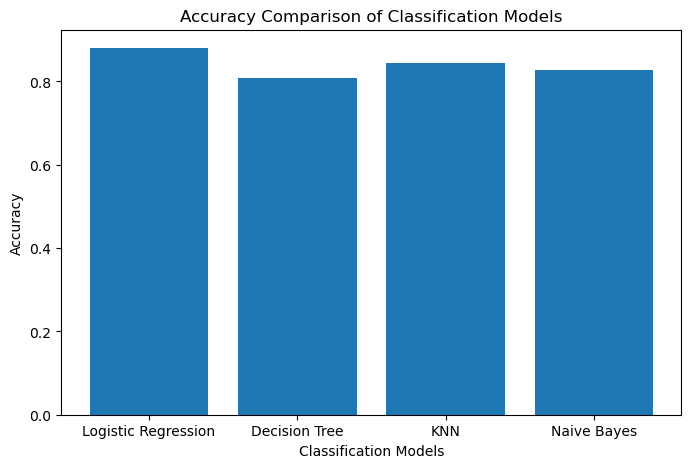

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Classification Models")

plt.show()

In [ ]:
best_index = results_df["F1 Score"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]
print("Best Model:", best_model_name)
print("Best F1 Score:",results_df.loc[best_index, "F1 Score"])

Best Model: Logistic Regression
Best F1 Score: 0.7961538461538461


In [ ]:
model_objects = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "KNN": knn,
    "Naive Bayes": nb
}
best_model = model_objects[best_model_name]
joblib.dump(best_model, "best_model.joblib")
print("Best model saved successfully!",best_model_name)


Best model saved successfully! Logistic Regression


In [ ]:
import joblib

joblib.dump(scaler, "scaler.joblib")
print("Scaler saved successfully!")
joblib.dump(scaler, "scaler.joblib")
print("Scaler saved successfully!")

NameError: name 'scaler' is not defined

In [ ]:
results_df.to_csv("model_comparison.csv", index=False)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [ ]:
# Load the saved model
saved_model = joblib.load("best_model.joblib")

# Select one student
sample = x_test.iloc[[0]]

# Scale the data because Logistic Regression is your best model
sample = scaler.transform(sample)

# Predict the outcome
prediction = saved_model.predict(sample)

print("Actual outcome:", y_test.iloc[0])
print("Predicted outcome:", prediction[0])


Actual outcome: Not Dropout
Predicted outcome: Not Dropout
